# Phase 4 · Demand forecast and inventory

**Business question 2:** How much will sell in the next 3 months, and how much inventory is needed?

We forecast **units sold per month**, the quantity that matters for inventory, for the three months after the last complete month of data: August, September and October 2018. First we compare several models on past data to choose one based on evidence, and then we use it to forecast total demand and the demand of each class A category, adding a safety stock to suggest inventory levels.

**Input:** the SQLite database `olist.db` and `category_summary.csv` (Phase 3).

**Outputs** in `data/processed/`:

| File | Content |
|---|---|
| `model_comparison.csv` | Errors of every model in the evaluation |
| `forecast_total.csv` | Forecast of total units and revenue for the next 3 months |
| `forecast_categories.csv` | Forecast, safety stock and suggested stock for each class A category |

## 1. Libraries, paths, chart style and SQL helper

In [1]:
import itertools
import sqlite3
import warnings
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

PROCESSED = Path("..") / "data" / "processed"
DATABASE = PROCESSED / "olist.db"
SQL_DIR = Path("..") / "sql"
FIGURES = Path("..") / "reports" / "figures"
pd.set_option("display.max_columns", 40)

BLUE = "#2a78d6"
LIGHT_BLUE = "#86b6ef"
GRAY = "#898781"
LIGHT_GRAY = "#c3c2b7"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": LIGHT_GRAY,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": SECONDARY_INK,
    "ytick.color": SECONDARY_INK,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
})

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def run_sql(name, show=True, parse_dates=None, **params):
    # Reads sql/<name>.sql, prints it and returns the result as a DataFrame
    query = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(query)
    with closing(sqlite3.connect(DATABASE)) as connection:
        return pd.read_sql_query(query, connection, params=params, parse_dates=parse_dates)

## 2. The monthly series

We reuse the Phase 3 query that returns units and revenue by category and month. August 2018 is left out because its data is incomplete from the 22nd on (Phase 1): if the models saw it, they would read the cutoff as a drop in sales. That leaves 19 complete months, from January 2017 to July 2018.

In [2]:
category_monthly = run_sql("category_monthly", parse_dates=["month"],
                           first_month="2017-01-01", last_month="2018-08-01",
                           start="2017-01-01", end="2018-09-01")

units = category_monthly.pivot(index="month", columns="category", values="units")
revenue = category_monthly.pivot(index="month", columns="category", values="revenue")
units.index = pd.PeriodIndex(units.index, freq="M")
revenue.index = pd.PeriodIndex(revenue.index, freq="M")

# Only complete months reach the models
units = units.loc[:"2018-07"]
revenue = revenue.loc[:"2018-07"]
total = units.sum(axis=1)
months = total.index

total.to_frame("units").T

-- Units and revenue by category and month, including zeros for months without sales.
-- A recursive CTE builds the calendar of months, which is crossed with every category.
WITH RECURSIVE months(month) AS (
    SELECT :first_month
    UNION ALL
    SELECT date(month, '+1 month')
    FROM months
    WHERE month < :last_month
),
categories AS (
    SELECT DISTINCT category
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
),
sales AS (
    SELECT
        strftime('%Y-%m-01', purchase_date) AS month,
        category,
        COUNT(*) AS units,
        SUM(price) AS revenue
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY month, category
)
SELECT
    m.month,
    c.category,
    COALESCE(s.units, 0) AS units,
    COALESCE(s.revenue, 0) AS revenue
FROM months AS m
CROSS JOIN categories AS c
LEFT JOIN sales AS s
    ON s.month = m.month
   AND s.category = c.category
ORDER BY m.month, c.category;



month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07
units,913,1858,2897,2569,4003,3489,4416,4797,4737,5214,8474,6187,8037,7518,8017,7827,7810,7007,6960


## 3. Why there are no seasonal models

The proposal planned to compare a moving average with Holt-Winters and SARIMA, two models that capture trend and yearly seasonality. To estimate a yearly pattern, a model needs to see every month of the year at least twice, that is, two full years (24 months). We have 19. This is what happens if we try to fit Holt-Winters with yearly seasonality anyway:

In [3]:
try:
    ExponentialSmoothing(total.to_numpy(dtype=float), trend="add", seasonal="add", seasonal_periods=12).fit()
except ValueError as error:
    print("Holt-Winters with yearly seasonality could not be fitted:")
    print(f"  {error}")
print(f"Complete months available: {len(total)}. Two full yearly cycles need 24.")

Holt-Winters with yearly seasonality could not be fitted:
  Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.
Complete months available: 19. Two full yearly cycles need 24.


SARIMA has the same problem: its seasonal part would be estimated from a single observation of each month. So we keep the non-seasonal version of each family: **Holt** (Holt-Winters without the seasonal component) and **ARIMA** (SARIMA without the seasonal part). We compare them with two simple baselines, because a complex model is only worth using if it beats them:

| Model | How it forecasts | Role |
|---|---|---|
| Naive | the next months repeat the last month | baseline |
| 3-month moving average | the average of the last three months | baseline |
| Holt with damped trend | a level and a trend that fades over time | trend model |
| ARIMA | order chosen automatically by AIC in each training window | autoregressive model |

For ARIMA we let the AIC choose the order among 9 simple options inside each training window. Choosing the order by hand after looking at the test results would make the model look better than it really is.

In [4]:
HORIZON = 3


def naive(train):
    return np.repeat(train[-1], HORIZON)


def moving_average(train):
    return np.repeat(train[-3:].mean(), HORIZON)


def holt_damped(train):
    return ExponentialSmoothing(train, trend="add", damped_trend=True).fit().forecast(HORIZON)


def arima_by_aic(train):
    best = None
    for p, q in itertools.product(range(3), range(3)):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                fitted = ARIMA(train, order=(p, 1, q)).fit()
            except (ValueError, np.linalg.LinAlgError):
                continue
        # Orders whose estimation did not converge are discarded
        if any(issubclass(warning.category, ConvergenceWarning) for warning in caught):
            continue
        if best is None or fitted.aic < best.aic:
            best = fitted
    return best.forecast(HORIZON)


MODELS = {
    "Naive (last month)": naive,
    "3-month moving average": moving_average,
    "Holt (damped trend)": holt_damped,
    "ARIMA (order chosen by AIC)": arima_by_aic,
}

## 4. How we evaluate the models

We hide the most recent months, let each model forecast them using only the earlier months, and compare the forecasts with what really happened. We do it in two ways:

- **Holdout**, as the proposal describes: the models are trained up to April 2018 and forecast May, June and July.
- **Rolling evaluation**: we repeat the same exercise five times, moving the cutoff from December 2017 to April 2018. That gives 15 forecasts per model instead of 3, so a lucky or unlucky month weighs less.

We measure two errors: **MAE**, the average error in units, and **MAPE**, the average error as a percentage of actual sales. **Decision rule, set before looking at the results:** we choose the model with the lowest MAPE in the rolling evaluation.

In [5]:
ROLLING_ORIGINS = pd.period_range("2017-12", "2018-04", freq="M")
HOLDOUT_ORIGIN = pd.Period("2018-04", freq="M")


def backtest(series, origins=ROLLING_ORIGINS):
    # One row per model, cutoff and forecast horizon, with the actual value and the forecast
    rows = []
    for origin in origins:
        cut = months.get_loc(origin) + 1
        train, test = series[:cut], series[cut:cut + HORIZON]
        for name, model in MODELS.items():
            for step, (actual, predicted) in enumerate(zip(test, model(train)), start=1):
                rows.append({"model": name, "origin": origin, "horizon": step,
                             "actual": actual, "forecast": predicted})
    result = pd.DataFrame(rows)
    result["error"] = result["actual"] - result["forecast"]
    result["abs_error"] = result["error"].abs()
    return result


total_backtest = backtest(total.to_numpy(dtype=float))
total_backtest["ape_pct"] = total_backtest["abs_error"] / total_backtest["actual"] * 100

holdout = total_backtest[total_backtest["origin"] == HOLDOUT_ORIGIN]
comparison = pd.DataFrame({
    "holdout_mae": holdout.groupby("model")["abs_error"].mean(),
    "holdout_mape_pct": holdout.groupby("model")["ape_pct"].mean(),
    "rolling_mae": total_backtest.groupby("model")["abs_error"].mean(),
    "rolling_mape_pct": total_backtest.groupby("model")["ape_pct"].mean(),
}).sort_values("rolling_mape_pct")

best_model = comparison.index[0]
print(f"Chosen model (lowest rolling MAPE): {best_model}")
comparison.round(1)

Chosen model (lowest rolling MAPE): 3-month moving average


,holdout_mae,holdout_mape_pct,rolling_mae,rolling_mape_pct
model,,,,
3-month moving average,543.4,7.8,595.2,7.8
Naive (last month),568.0,8.1,664.7,8.7
Holt (damped trend),2035.9,28.6,1106.7,14.9
ARIMA (order chosen by AIC),734.9,10.5,1267.3,16.7


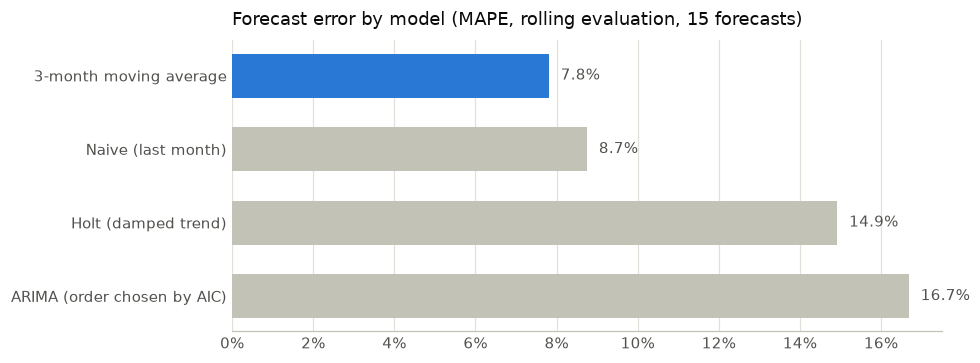

In [6]:
ordered = comparison["rolling_mape_pct"].iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(ordered.index, ordered.to_numpy(),
        color=[BLUE if name == best_model else LIGHT_GRAY for name in ordered.index], height=0.6)
for row, value in enumerate(ordered):
    ax.text(value + 0.3, row, f"{value:.1f}%", va="center", color=SECONDARY_INK)
ax.set_title("Forecast error by model (MAPE, rolling evaluation, 15 forecasts)")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "04_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

The two simple baselines beat the more complex models. The 3-month moving average has the lowest error in both evaluations, 7.8% in the rolling evaluation and 7.8% in the holdout, while Holt and ARIMA do much worse (14.9% and 16.7% in the rolling evaluation).

The reason is the shape of the series. Sales grew fast during 2017 and then leveled off in 2018. Holt learns the 2017 growth and keeps projecting it, so it overshoots: in the holdout it forecast more than 8,800 units per month when actual sales were between 6,960 and 7,810. ARIMA has to estimate its parameters with only 12 to 16 months in each window, and with so little data its forecasts are unstable.

Following the rule set in advance, we choose the 3-month moving average. It is also the easiest model to explain and to recalculate every month.

## 5. Forecast of total demand

We train the chosen model on the 19 complete months and forecast August, September and October 2018. To express the uncertainty we use the model's own errors in the rolling evaluation: the forecast range is the forecast plus and minus 1.65 times the root mean squared error (RMSE), which covers about 90% of the errors if they behave like in the past. We forecast revenue with the same model.

In [7]:
FORECAST_MONTHS = pd.period_range("2018-08", "2018-10", freq="M")
Z = 1.65

chosen = MODELS[best_model]
best_errors = total_backtest.loc[total_backtest["model"] == best_model, "error"]
total_rmse = np.sqrt((best_errors ** 2).mean())

forecast_total = pd.DataFrame({
    "forecast_units": chosen(total.to_numpy(dtype=float)),
    "lower_units": chosen(total.to_numpy(dtype=float)) - Z * total_rmse,
    "upper_units": chosen(total.to_numpy(dtype=float)) + Z * total_rmse,
    "forecast_revenue": chosen(revenue.sum(axis=1).to_numpy(dtype=float)),
}, index=FORECAST_MONTHS)
forecast_total.index.name = "month"

print(f"RMSE of the chosen model in the rolling evaluation: {total_rmse:,.0f} units")
forecast_total.round(0)

RMSE of the chosen model in the rolling evaluation: 742 units


,forecast_units,lower_units,upper_units,forecast_revenue
month,,,,
2018-08,7259.0,6034.0,8484.0,900208.0
2018-09,7259.0,6034.0,8484.0,900208.0
2018-10,7259.0,6034.0,8484.0,900208.0


We have one way to check the forecast against reality. The data for August 2018 is incomplete, but the first 21 days are reliable. If we project their pace to the whole month, we get an estimate of what August really looked like:

In [8]:
august = run_sql("units_between", start="2018-08-01", end="2018-08-22")
august_units = august["units"].iloc[0]
august_pace = august_units / 21 * 31
august_forecast = forecast_total.loc["2018-08", "forecast_units"]

print(f"Units sold from August 1 to 21: {august_units:,} ({august_units / 21:.0f} per day)")
print(f"Projected to 31 days: {august_pace:,.0f} units")
print(f"Forecast for August: {august_forecast:,.0f} units "
      f"(upper end of the range: {forecast_total.loc['2018-08', 'upper_units']:,.0f})")
print(f"The forecast falls short by {1 - august_forecast / august_pace:.1%}")

-- Units sold between two dates (the end date is excluded)
SELECT
    COUNT(*) AS units
FROM items
WHERE purchase_date >= :start
  AND purchase_date < :end;

Units sold from August 1 to 21: 6,362 (303 per day)
Projected to 31 days: 9,392 units
Forecast for August: 7,259 units (upper end of the range: 8,484)
The forecast falls short by 22.7%


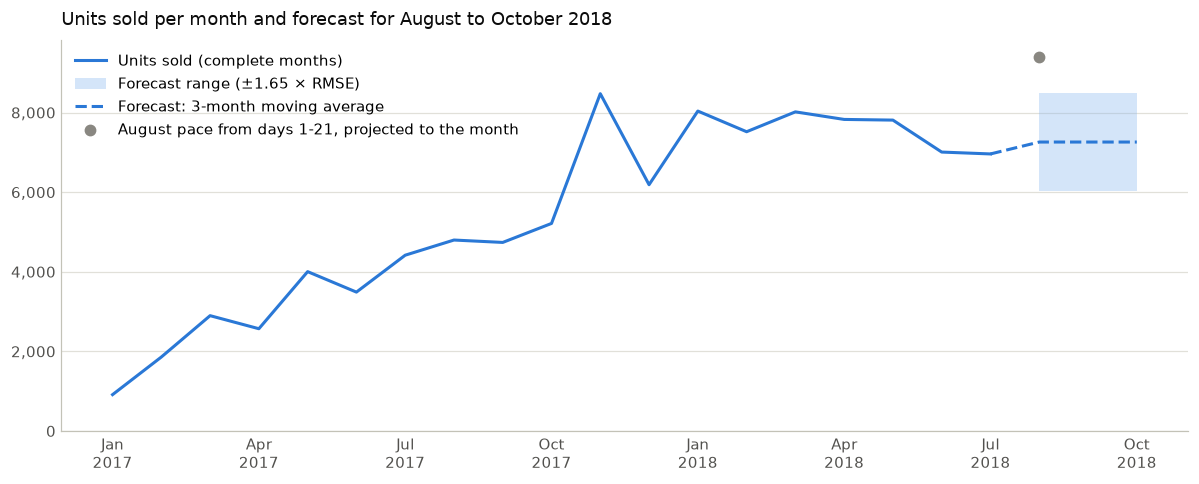

In [9]:
history_x = np.arange(len(total))
forecast_x = np.arange(len(total), len(total) + len(FORECAST_MONTHS))
all_months = list(months) + list(FORECAST_MONTHS)
tick_positions = [i for i, month in enumerate(all_months) if month.month in (1, 4, 7, 10)]
tick_labels = [f"{MONTHS[all_months[i].month - 1]}\n{all_months[i].year}" for i in tick_positions]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(history_x, total.to_numpy(), color=BLUE, linewidth=2, label="Units sold (complete months)")
ax.fill_between(forecast_x, forecast_total["lower_units"], forecast_total["upper_units"],
                color=LIGHT_BLUE, alpha=0.35, linewidth=0, label="Forecast range (±1.65 × RMSE)")
ax.plot(np.r_[history_x[-1], forecast_x], np.r_[total.iloc[-1], forecast_total["forecast_units"]],
        color=BLUE, linewidth=2, linestyle="--", label=f"Forecast: {best_model.lower()}")
ax.scatter([forecast_x[0]], [august_pace], color=GRAY, s=45, zorder=3,
           label="August pace from days 1-21, projected to the month")

ax.set_xticks(tick_positions, tick_labels)
ax.set_title("Units sold per month and forecast for August to October 2018")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.set_ylim(0, None)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "04_total_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

The model forecasts 7,259 units per month for August, September and October 2018, with a range between 6,034 and 8,484 units, and revenue of about R$ 900,000 per month.

The August check is a warning. In the first 21 days of August customers bought 303 units per day, which projected to the whole month gives 9,392 units. The forecast falls 22.7% short of that pace, and the pace is even above the upper end of the range. No model trained only on the previous months could anticipate this jump, because nothing in those months announced it: a moving average reacts to a change only after it happens.

This is a limitation of forecasting with 19 months of history. The models capture the current level of sales, not sudden shifts, so the forecast is a starting point that has to be reviewed every month with the latest sales.

## 6. Forecast and suggested inventory by category

Inventory is managed product by product, or at least category by category. We forecast the 18 class A categories from Phase 3, which bring in 80% of revenue.

First we repeat the model comparison at category level. Here we measure the error with **WAPE** (total absolute error divided by total actual units) instead of MAPE: some categories had months with zero sales, and MAPE divides by the actual value, so it cannot be computed for those months.

In [10]:
a_categories = (
    pd.read_csv(PROCESSED / "category_summary.csv")
    .query("abc_class == 'A'")["category"]
    .tolist()
)

category_backtest = pd.concat(
    [backtest(units[category].to_numpy(dtype=float)).assign(category=category) for category in a_categories],
    ignore_index=True,
)
by_model = category_backtest.groupby("model")
category_wape = (by_model["abs_error"].sum() / by_model["actual"].sum() * 100).sort_values()
category_wape.round(1).to_frame("wape_pct")

,wape_pct
model,
Naive (last month),23.9
ARIMA (order chosen by AIC),24.5
3-month moving average,24.8
Holt (damped trend),28.2


At category level the errors are much larger, around 24%, because each category sells less than the total and more irregularly. The naive forecast, ARIMA and the moving average are within one point of each other (23.9% to 24.8%), a difference too small to matter. We keep the moving average: it is the model chosen for the total series, and it is steadier than the naive forecast, which copies whatever happened in the last month.

For each category, the suggested stock for a month is the forecast plus a **safety stock**:

- **Safety stock** = 1.65 × the RMSE of the model's errors for that category in the rolling evaluation. The factor 1.65 corresponds to a 95% service level: if forecast errors behave like in the past, the stock covers demand in about 19 months out of 20.
- We assume stock is replenished once a month and suppliers deliver within that month. With longer delivery times the safety stock has to grow, because it must cover more uncertainty.

In [11]:
chosen_errors = category_backtest[category_backtest["model"] == best_model]
error_stats = chosen_errors.groupby("category").agg(
    rmse=("error", lambda errors: np.sqrt((errors ** 2).mean())),
    abs_error=("abs_error", "sum"),
    actual=("actual", "sum"),
)

inventory = pd.DataFrame(index=pd.Index(a_categories, name="category"))
inventory["forecast_per_month"] = [chosen(units[c].to_numpy(dtype=float))[0] for c in a_categories]
inventory["safety_stock"] = Z * error_stats["rmse"]
inventory["suggested_monthly_stock"] = np.ceil(inventory["forecast_per_month"] + inventory["safety_stock"])
inventory["wape_pct"] = error_stats["abs_error"] / error_stats["actual"] * 100
inventory = inventory.sort_values("suggested_monthly_stock", ascending=False)
inventory.round(1)

,forecast_per_month,safety_stock,suggested_monthly_stock,wape_pct
category,,,,
Health beauty,798.7,240.3,1040.0,19.0
Computers accessories,423.7,546.9,971.0,49.7
Housewares,586.3,240.0,827.0,25.8
Bed bath table,707.0,114.4,822.0,7.1
Watches gifts,540.3,227.0,768.0,24.0
Sports leisure,456.0,255.2,712.0,23.7
Furniture decor,478.3,162.6,641.0,16.6
Auto,314.7,95.6,411.0,15.2
Toys,187.0,216.5,404.0,49.4


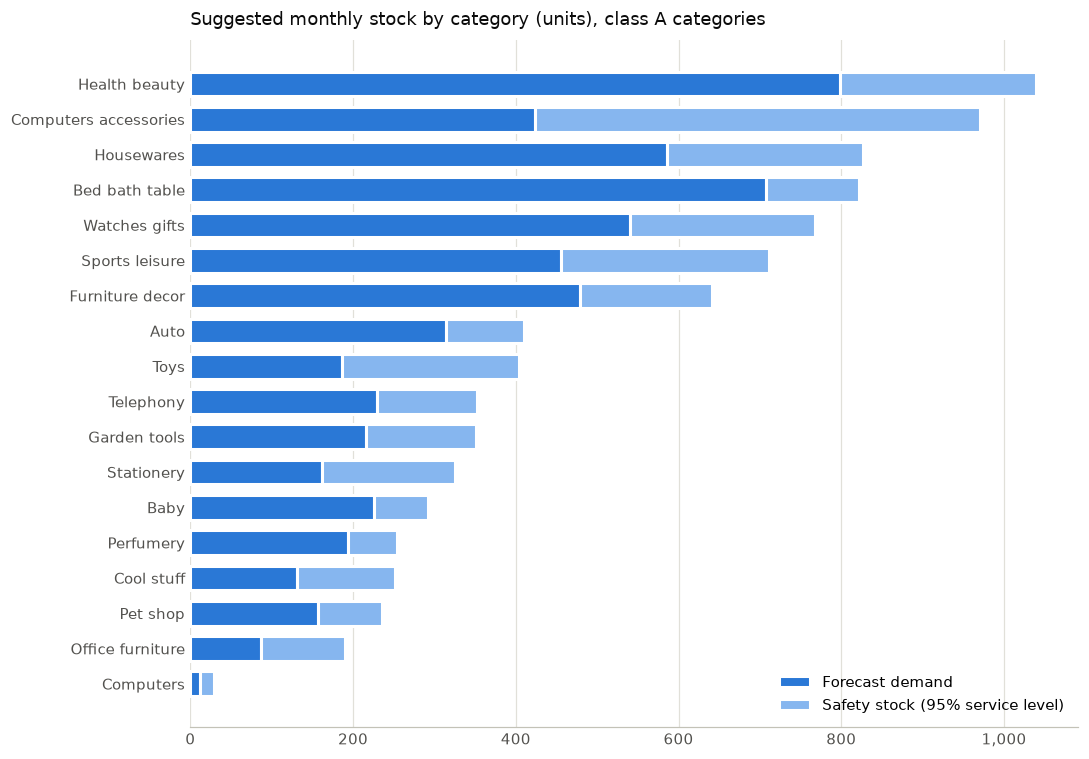

In [12]:
ordered = inventory.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(ordered.index, ordered["forecast_per_month"], color=BLUE, height=0.7,
        edgecolor="white", linewidth=2, label="Forecast demand")
ax.barh(ordered.index, ordered["safety_stock"], left=ordered["forecast_per_month"], color=LIGHT_BLUE,
        height=0.7, edgecolor="white", linewidth=2, label="Safety stock (95% service level)")
ax.set_title("Suggested monthly stock by category (units), class A categories")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "04_inventory_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

The suggested stock goes from 1,040 units per month for Health beauty to 30 for Computers. The last column (WAPE) shows how reliable each forecast is, and it splits the categories into two groups:

- Stable categories, such as Bed bath table (7.1% error), Auto (15.2%) and Perfumery (15.7%). The forecast is a good guide for them, and the safety stock stays small compared with demand.
- Irregular categories, with errors close to 50%. Computers accessories had a temporary surge in early 2018, from 284 units in December to 971 in February, before returning to about 400. Toys peaks in November and December. Stationery peaked in January 2018, consistent with back-to-school shopping in Brazil, where the school year starts in February. In these three categories the safety stock ends up as large as the forecast or larger, a sign that the average is not enough to plan them.

Computers is a special case. It is class A because it sells very expensive items, but it sells only a few units per month and had two months without sales in 2018 (108.8% error). An average cannot plan this kind of intermittent demand, so these items are better ordered on demand.

## 7. Saving

In [13]:
forecast_categories = inventory.reset_index().merge(
    pd.DataFrame({"month": FORECAST_MONTHS.to_timestamp()}), how="cross"
)[["category", "month", "forecast_per_month", "safety_stock", "suggested_monthly_stock", "wape_pct"]]

outputs = {
    "model_comparison.csv": comparison.reset_index(),
    "forecast_total.csv": forecast_total.reset_index().assign(month=lambda df: df["month"].dt.to_timestamp()),
    "forecast_categories.csv": forecast_categories,
}
for name, table in outputs.items():
    table.to_csv(PROCESSED / name, index=False, float_format="%.2f")
    print(f"{name:<26} {len(table):>5,} rows")

model_comparison.csv           4 rows
forecast_total.csv             3 rows
forecast_categories.csv       54 rows


## Answer to business question 2

**Business question.** How much will sell in the next 3 months, and how much inventory is needed?

**Analysis.** We compared two simple baselines (naive and 3-month moving average) with Holt and ARIMA on the 19 complete months of data, using a holdout and a rolling evaluation with 15 forecasts, and chose the model with the lowest MAPE. With that model we forecast total units and revenue for August to October 2018 and the demand of the 18 class A categories, adding a safety stock based on each category's past forecast errors.

**Evidence.**

- The 3-month moving average had the lowest error (7.8% MAPE), ahead of the naive forecast (8.7%), Holt (14.9%) and ARIMA (16.7%). Seasonal models could not be fitted: they need at least 24 months of history, and there are 19.
- Forecast: 7,259 units and about R$ 900,000 in revenue per month, with a range of 6,034 to 8,484 units.
- The first 21 days of August ran at 303 units per day. Projected to the month, that pace leaves the forecast 22.7% short: the models did not anticipate the jump.
- At category level the error rises to about 24%, ranging from 7.1% in Bed bath table to 108.8% in Computers.

**Insight.** With a short history, simple models forecast better than complex ones, because the 2017 growth misleads the trend models. The forecast is reliable for the overall level of demand, not for sudden jumps, and its quality varies a lot between categories: stable categories can be planned with it, while irregular or seasonal ones need more than an average.

**Recommendation.**

1. Plan monthly purchases with the 3-month moving average and recalculate it every month with the latest sales.
2. Keep a safety stock per category based on its own forecast error, as in the table above, and update it when the error changes.
3. For seasonal or irregular categories (Toys, Stationery, Computers accessories), adjust the plan with the business calendar, such as Christmas or back to school, instead of relying on the average.
4. Order expensive items with intermittent demand, such as Computers, on demand instead of keeping them in stock.
5. Compare actual sales with the forecast range every week. A month like August 2018, running above the upper end, calls for an early restock.

**Application to the machinery business.** The same process works with the business's data, with three adjustments:

- Machinery suppliers can take weeks or months to deliver, while this analysis assumed delivery within the month. The safety stock grows with the delivery time: with a lead time of L months, it is multiplied by the square root of L.
- Tractors and implements behave like Computers here: few units, high value and intermittent demand, which are better managed by order than by forecast. The forecast is most useful for spare parts, which sell more steadily.
- Agricultural sales follow the planting and harvest calendar. Once the business has at least two years of data, seasonal models such as Holt-Winters and SARIMA become viable and should be compared again with the same method.

**Limitations.** The history covers 19 months, without a complete yearly cycle; forecasts are monthly only; and the safety stock assumes that future errors will look like past ones. Olist is a marketplace where sellers hold the stock, so the inventory figures illustrate the method rather than an actual purchase plan.